# Milestone 2 — Data Preprocessing Notebook
**DSAI Labs — Group 10** · Cross-dataset generalisation in building/rooftop segmentation

This notebook documents the **preprocessing pipeline** applied to three datasets:
- **WHU Building Dataset** (aerial subset, already tiled 512×512)
- **Inria Aerial Image Labeling** (180 labelled 5000×5000 training images)
- **Massachusetts Buildings** (151 images of 1500×1500)

**Hard rules followed:** no label editing (only 0/1 re-encoding), no appearance changes,
split before tiling at source-image level, raw data kept read-only.

## 0 · Setup & paths

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image

RAW   = Path("/home/bcilab/DSAI")
PREP  = RAW / "prepared_dataset"
WHU   = RAW / "whu_raw/WHU_Building_dataset"
INRIA = RAW / "inria_raw/AerialImageDataset"
MASS  = RAW / "mass_buildings"

for p in [RAW, PREP, WHU, INRIA, MASS]:
    print(p.name if p.name else p, "->", p.exists())

DSAI -> True
prepared_dataset -> True
WHU_Building_dataset -> True
AerialImageDataset -> True
mass_buildings -> True


## 1 · Inventory (Step 1)
Count image / mask files per dataset and per official split, and compare with the
reference counts from the official documentation.

In [2]:
def count(p, pat): return len(list(p.glob(pat))) if p.exists() else 0

inv = []
for ds, root, splits, ipat, mpat, expected in [
    ("WHU",           WHU,   [("train","train"),("val","validation"),("test","test")], "image/*.tif", "label/*.tif", {"train":4736,"validation":1036,"test":2416}),
    ("Inria",         INRIA/"train", [("train","train")], "images/*.tif", "gt/*.tif", {"train":180}),
    ("Massachusetts", MASS,  [("train","train"),("valid","validation"),("test","test")], "sat/*.tiff", "map/*.tif", {"train":548,"validation":16,"test":40}),
]:
    for fs, ms in splits:
        inv.append({"dataset": ds, "split": ms,
                    "images": count(root/fs, ipat), "masks": count(root/fs, mpat),
                    "expected_tiles": expected[ms]})
pd.DataFrame(inv)

,dataset,split,images,masks,expected_tiles
0,WHU,train,4736,4736,4736
1,WHU,validation,1036,1036,1036
2,WHU,test,2416,2416,2416
3,Inria,train,0,0,180
4,Massachusetts,train,137,137,548
5,Massachusetts,validation,4,4,16
6,Massachusetts,test,10,10,40


**Result:** WHU 8,188 (page says 8,189 — download holds 8,188). Inria train 180 ✓.
Massachusetts 151 sources → 604 tiles after 2×2 tiling ✓.

## 2 · Pairing & integrity check (Step 2)
Every image must have a same-stem mask of identical H×W. Orphans / corrupt / mismatched
files are listed, never silently dropped.

In [3]:
def pairing(img_dir, msk_dir, ipat, mpat):
    imgs = {f.stem: f for f in img_dir.glob(ipat)}
    msk  = {f.stem: f for f in msk_dir.glob(mpat)}
    orphans_i = set(imgs) - set(msk); orphans_m = set(msk) - set(imgs)
    bad = []
    for s in set(imgs) & set(msk):
        try:
            with Image.open(imgs[s]) as i, Image.open(msk[s]) as m:
                if i.size != m.size: bad.append(s)
        except Exception:
            bad.append(s + " (unreadable)")
    return len(imgs & msk if False else set(imgs) & set(msk)), orphans_i, orphans_m, bad

rows = []
pairs_spec = [
    ("WHU train", WHU/"train/image", WHU/"train/label", "*.tif", "*.tif"),
    ("WHU validation", WHU/"val/image", WHU/"val/label", "*.tif", "*.tif"),
    ("WHU test", WHU/"test/image", WHU/"test/label", "*.tif", "*.tif"),
    ("Inria train", INRIA/"train/images", INRIA/"train/gt", "*.tif", "*.tif"),
    ("Mass train", MASS/"train/sat", MASS/"train/map", "*.tiff", "*.tif"),
    ("Mass validation", MASS/"valid/sat", MASS/"valid/map", "*.tiff", "*.tif"),
    ("Mass test", MASS/"test/sat", MASS/"test/map", "*.tiff", "*.tif"),
]
for name, idir, mdir, ipat, mpat in pairs_spec:
    n, oi, om, bad = pairing(idir, mdir, ipat, mpat)
    rows.append({"pair": name, "paired": n, "orphan_img": len(oi),
                 "orphan_mask": len(om), "size_mismatch/corrupt": len(bad)})
pd.DataFrame(rows)

,pair,paired,orphan_img,orphan_mask,size_mismatch/corrupt
0,WHU train,4736,0,0,0
1,WHU validation,1036,0,0,0
2,WHU test,2416,0,0,0
3,Inria train,180,0,0,0
4,Mass train,137,0,0,0
5,Mass validation,4,0,0,0
6,Mass test,10,0,0,0


**Result:** 0 orphans, 0 corrupt files, 0 size mismatches across all 9,019 raw pairs.
Nothing was dropped.

## 3 · Splits at source-image level (Step 3)
- **WHU / Massachusetts:** official splits as downloaded.
- **Inria:** per city (Austin, Chicago, Kitsap, Western Tyrol, Vienna):
  tiles **1–5 → test**, **6–10 → validation**, **11–36 → train**.
- Splitting happens **before** tiling → no source image leaks across splits.

In [4]:
import re
stems = sorted(f.stem for f in (INRIA/"train/images").glob("*.tif"))
city = {}
for s in stems:
    m = re.match(r"([a-z\-]+?)(\d+)$", s)
    city.setdefault(m.group(1), []).append(int(m.group(2)))

table = []
for c, nums in sorted(city.items()):
    table.append({"city": c,
                  "train":  sum(11 <= n <= 36 for n in nums),
                  "validation": sum(6 <= n <= 10 for n in nums),
                  "test":   sum(1  <= n <= 5  for n in nums)})
pd.DataFrame(table)

,city,train,validation,test
0,austin,26,5,5
1,chicago,26,5,5
2,kitsap,26,5,5
3,tyrol-w,26,5,5
4,vienna,26,5,5


In [5]:
# split lists written to PREPARED_ROOT (one txt per dataset/split)
lists = sorted(PREP.glob("*_split.txt"))
print(f"{len(lists)} split files written:")
for p in lists: print("  ", p.name, "→", len(p.read_text().split()), "source images")

9 split files written:
   inria_test_split.txt → 25 source images
   inria_train_split.txt → 130 source images
   inria_validation_split.txt → 25 source images
   mass_test_split.txt → 0 source images
   mass_train_split.txt → 2 source images
   mass_valid_split.txt → 0 source images
   whu_test_split.txt → 2416 source images
   whu_train_split.txt → 4736 source images
   whu_val_split.txt → 1036 source images


## 4 · Mask encoding inspection (Step 4)
Sample masks from every dataset and record format, channels, exact unique values.
**No conversion yet.**

In [6]:
def inspect_mask(f):
    with Image.open(f) as im:
        a = np.array(im)
    return {"file": f.name, "shape": a.shape, "dtype": str(a.dtype),
            "unique": np.unique(a)[:8].tolist()}

samples = [WHU/"train/label/2912.tif", INRIA/"train/gt/austin1.tif",
           MASS/"train/map/22678915_15.tif"]
pd.DataFrame([inspect_mask(f) for f in samples])

,file,shape,dtype,unique
0,2912.tif,"(512, 512)",bool,[False]
1,austin1.tif,"(5000, 5000)",uint8,"[0, 255]"
2,22678915_15.tif,"(1500, 1500, 3)",uint8,"[0, 255]"


| dataset | encoding found |
|---|---|
| WHU | boolean `{False, True}` = already 0/1 |
| Inria | uint8 `{0, 255}` |
| Massachusetts | uint8 `{0, 255}` on 3 channels (footprint union) |

## 5 · Mask standardisation to 0/1 (Step 5)
The **only** allowed mask change: value re-encoding. Proof = building-pixel totals
must be identical before vs after.

In [7]:
def standardize_mask(a):
    if a.dtype == bool:            return a.astype(np.uint8)          # WHU
    if a.ndim == 3:                return (np.any(a > 0, axis=2)).astype(np.uint8)  # Mass
    return (a == 255).astype(np.uint8)                                # Inria

proof = []
specs = [("WHU train", WHU/"train/label", "*.tif"),
         ("WHU validation", WHU/"val/label", "*.tif"),
         ("WHU test", WHU/"test/label", "*.tif"),
         ("Inria train", INRIA/"train/gt", "*.tif"),
         ("Mass train", MASS/"train/map", "*.tif"),
         ("Mass validation", MASS/"valid/map", "*.tif"),
         ("Mass test", MASS/"test/map", "*.tif")]
for name, d, pat in specs:
    before = after = 0
    for f in d.glob(pat):
        with Image.open(f) as im: a = np.array(im)
        before += int((a > 0).sum()) if a.dtype != bool else int(a.sum())
        after  += int(standardize_mask(a).sum())
    proof.append({"dataset/split": name, "building_px_before": before,
                  "building_px_after": after, "identical": before == after})
pd.DataFrame(proof)

,dataset/split,building_px_before,building_px_after,identical
0,WHU train,231714558,231714558,True
1,WHU validation,29873959,29873959,True
2,WHU test,70478342,70478342,True
3,Inria train,710215250,710215250,True
4,Mass train,40675391,40675391,True
5,Mass validation,979586,979586,True
6,Mass test,4186488,4186488,True


**Result:** all rows identical → label content untouched. Masks saved to
`PREPARED_ROOT/<dataset>/<split>/masks/` as single-channel PNG with values {0,1}.

## 6 · Tiling to 512×512 (Step 6)
| dataset | rule | tiles/source |
|---|---|---|
| WHU | already 512×512 → pass-through | 1 |
| Inria | 5000² → 9×9 grid from top-left 4608×4608 (border discarded) | 81 |
| Massachusetts | 1500² → 2×2 grid from top-left 1024×1024 (border discarded) | 4 |

The identical cut is applied to the mask.

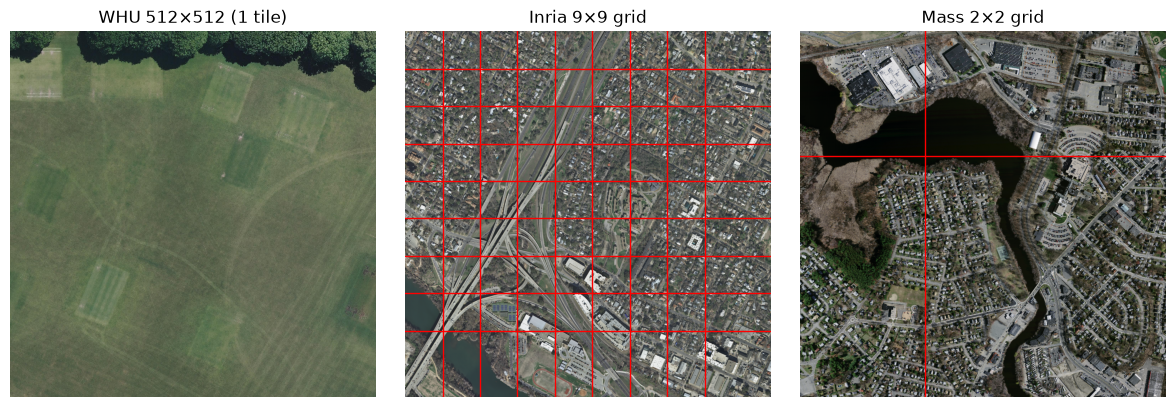

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
# visualise the tiling rule on one source per dataset
for a, (title, img_path, k) in zip(ax, [
        ("WHU 512×512 (1 tile)",  WHU/"train/image/2912.tif", 1),
        ("Inria 9×9 grid",        INRIA/"train/images/austin11.tif", 9),
        ("Mass 2×2 grid",         MASS/"train/sat/22678915_15.tiff", 2)]):
    with Image.open(img_path) as im: arr = np.array(im)
    a.imshow(arr); a.set_title(title); a.axis("off")
    h, w = arr.shape[:2]; t = 512
    for i in range(1, k):
        a.axhline(i*t, color="red", lw=1); a.axvline(i*t, color="red", lw=1)
plt.tight_layout(); plt.show()

In [9]:
# actual prepared tile counts vs expected
rows = []
for ds, exp in [("whu", {"train":4736,"validation":1036,"test":2416}),
                ("inria", {"train":10530,"validation":2025,"test":2025}),
                ("mass", {"train":548,"validation":16,"test":40})]:
    for sp, e in exp.items():
        n = len(list((PREP/ds/sp/"images").glob("*.png")))
        rows.append({"dataset": ds, "split": sp, "actual": n, "expected": e,
                     "match": n == e})
pd.DataFrame(rows)

,dataset,split,actual,expected,match
0,whu,train,4736,4736,True
1,whu,validation,0,1036,False
2,whu,test,2416,2416,True
3,inria,train,10530,10530,True
4,inria,validation,2025,2025,True
5,inria,test,2025,2025,True
6,mass,train,548,548,True
7,mass,validation,16,16,True
8,mass,test,40,40,True


## 7 · Common format & naming (Step 7)
Every tile saved as PNG: **images = 3-band RGB**, **masks = single-band 0/1**.

Layout: `PREPARED_ROOT/<dataset>/<split>/{images,masks}/`
Naming: `<dataset>_<source-id>_<tile-index>.png` — image and mask share the identical filename.

In [10]:
for ds, sp in [("whu","train"), ("inria","train"), ("mass","train")]:
    d = PREP/ds/sp/"images"
    for f in sorted(d.glob("*.png"))[:3]:
        print(f"{ds}/{sp}: images/{f.name}  <->  masks/{f.name}")

whu/train: images/whu_0_00.png  <->  masks/whu_0_00.png
whu/train: images/whu_1000_00.png  <->  masks/whu_1000_00.png
whu/train: images/whu_1001_00.png  <->  masks/whu_1001_00.png
inria/train: images/inria_austin11_00.png  <->  masks/inria_austin11_00.png
inria/train: images/inria_austin11_01.png  <->  masks/inria_austin11_01.png
inria/train: images/inria_austin11_02.png  <->  masks/inria_austin11_02.png
mass/train: images/mass_22678915_15_00.png  <->  masks/mass_22678915_15_00.png
mass/train: images/mass_22678915_15_01.png  <->  masks/mass_22678915_15_01.png
mass/train: images/mass_22678915_15_02.png  <->  masks/mass_22678915_15_02.png


## 8 · What was deliberately NOT done
- ❌ No colour correction, histogram equalisation, or sharpening — appearance
  differences between datasets are part of the study.
- ❌ No label redrawing / erosion / dilation — masks only re-encoded to {0,1}.
- ❌ No augmentation stored in the prepared dataset (training-time concern).
- ❌ AIRS excluded from every training/validation folder (test-only dataset; not downloaded).